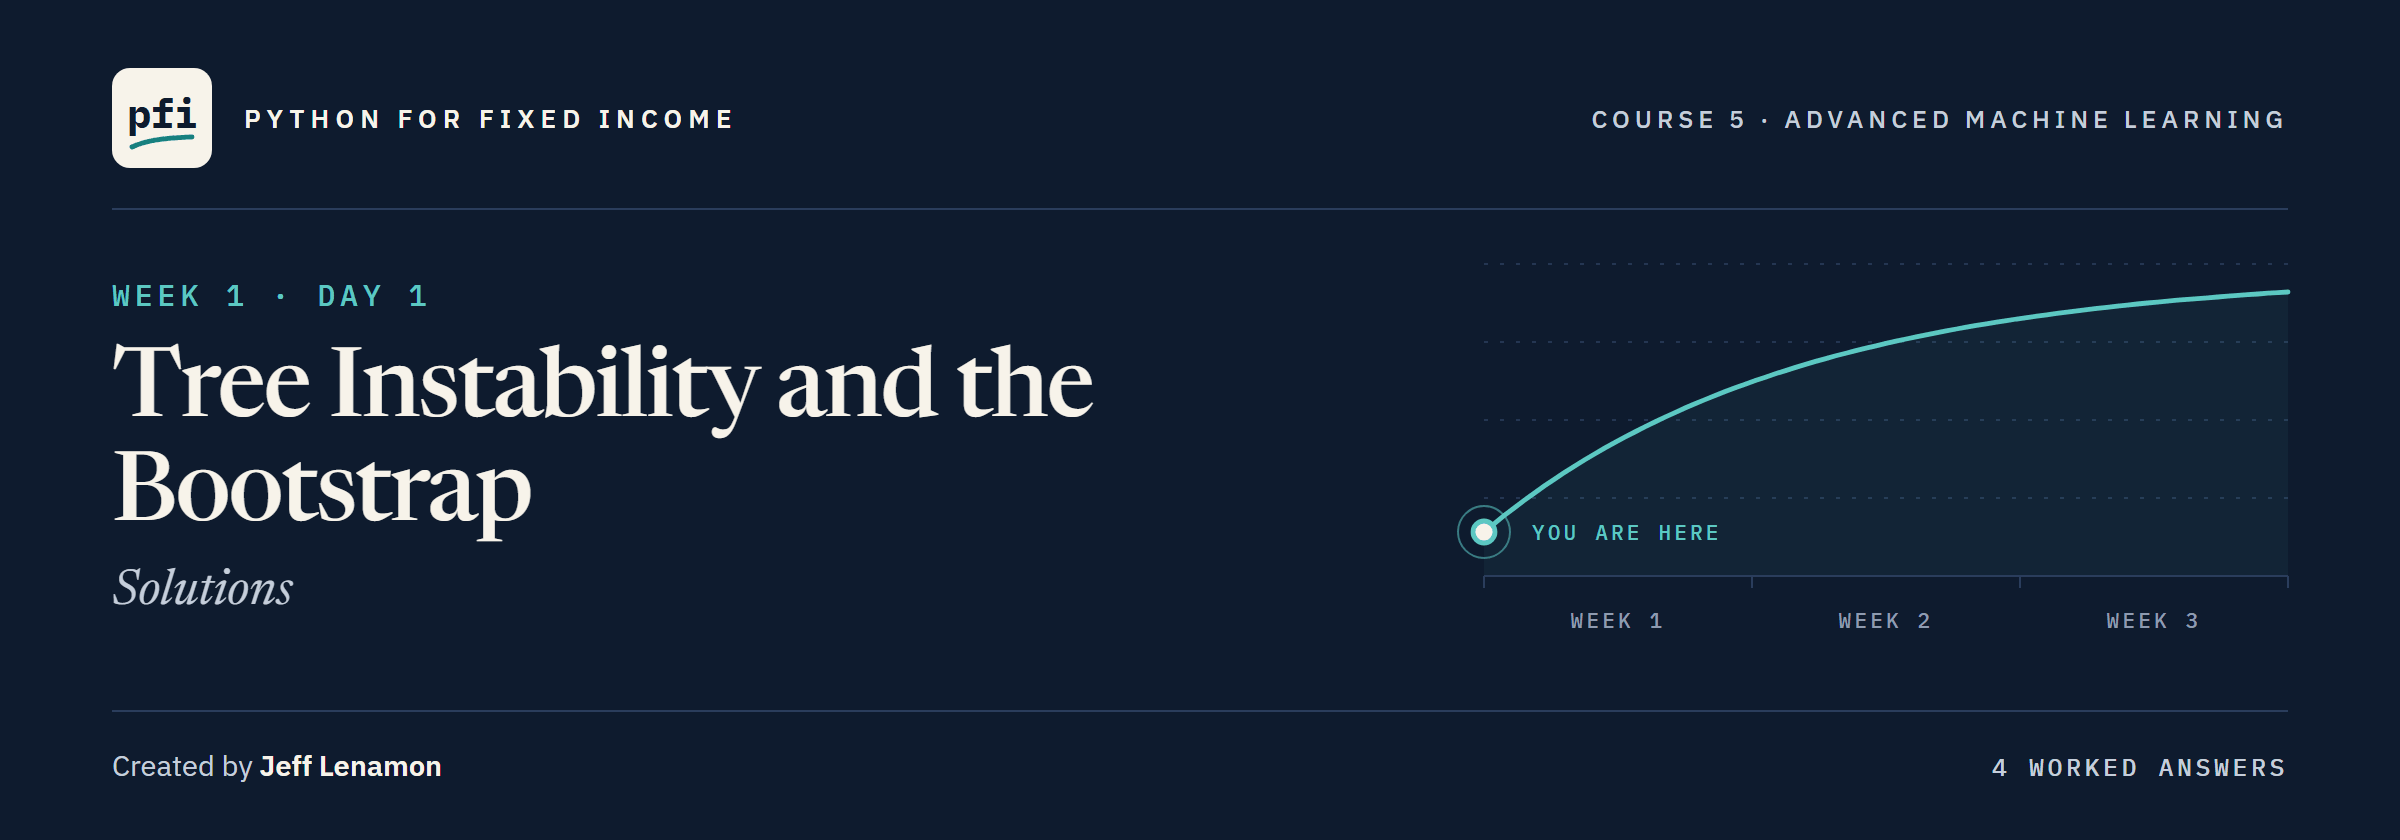

# Tree Instability and the Bootstrap: Solutions

Week 1, Day 1. The full notebook with every exercise worked. Try each one yourself first.

**Data:** `credit_card_default.csv`, 30,000 card accounts in Taiwan in 2005: **real**, UCI Machine Learning Repository dataset 350, CC BY 4.0. Citation: Yeh, I. (2009). Default of Credit Card Clients [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week1/day1/01_tree_instability_and_the_bootstrap_solutions.ipynb)

# Problem Statement

## Business Context

Course 5 combines many models into one: bagging, random forests, boosting and stacking, then reads what the combined model leans on.
It starts where Course 4 ended, with the card file's 18,000 training and 6,000 validation accounts, trees, pruning, cross-validation and ROC AUC.
Course 4's Day 9 ended with a 12-rule pruned tree a credit committee could read, and a reviewer asks one question: had the bank kept a different 18,000 accounts, would a tree say the same thing about this account?
The bootstrap draws other plausible training sets from the one we have, so we can answer by experiment.
The accounts are real, from Taiwan in 2005, so they describe consumer credit there and then, not US credit today.
The four person columns are never features, because a model that used them would sort people by them.

## Objectives

Rebuild Course 4's rows and its two trees, draw a bootstrap sample and count the accounts it leaves out, and fit a tree on each of ten samples.
Measure how far one account's output moves from tree to tree, compare deep and shallow trees, average the trees and score the average on validation rows, and name the rows each tree never saw.

## Data Dictionary

`credit_card_default.csv`, one row per account:

1. `LIMIT_BAL`: credit limit, NT dollars
2. `PAY_0`, `PAY_2` to `PAY_6`: repayment status, September back to April 2005, where -1 is paid on time, 1 to 9 is months late, and -2 and 0 are undocumented (used as numbers, a modelling choice, as in Course 4)
3. `BILL_AMT1` to `BILL_AMT6`: the bill, NT dollars, September back to April
4. `PAY_AMT1` to `PAY_AMT6`: the amount paid, NT dollars, September back to April
5. `default payment next month`: 1 if the account defaulted the following month, **the target**
6. `ID`, `SEX`, `EDUCATION`, `MARRIAGE`, `AGE`: never used

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and a dropdown
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# to split the accounts
from sklearn.model_selection import train_test_split

# to build and draw decision trees
from sklearn.tree import DecisionTreeClassifier, plot_tree

# to score a model's outputs
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:.4f}".format)

# Loading the Data

## Reading the Card File

In [3]:
# the 30,000 accounts; the target's name has spaces, so we keep it in a variable
card = pd.read_csv(DATA + "credit_card_default.csv")
TARGET = "default payment next month"

# every column except the ID, the four person columns and the target
X = card.drop(columns=["ID", "SEX", "EDUCATION", "MARRIAGE", "AGE", TARGET])
y = card[TARGET]
FEATURES = list(X.columns)
print(len(FEATURES), "features")

19 features


## Checking the Shape and the Default Share

In [4]:
# rows and columns, and how many accounts defaulted
print(card.shape)
print("Defaults:", y.sum(), " Share:", round(y.mean() * 100, 2), "percent")

(30000, 25)
Defaults: 6636  Share: 22.12 percent


**The file Course 4 used, unchanged, so we rebuild its rows exactly.**

# Data Preparation for Modeling

## Course 4's Split

In [5]:
# Course 4's split: a fifth of the accounts to test, then a quarter of the rest to validation, defaults spread evenly
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_valid, y_train, y_valid = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=SEED)
print("Training:", len(X_train), " Validation:", len(X_valid), " Test:", len(X_test))
print("Default share:", round(y_train.mean(), 4), round(y_valid.mean(), 4), round(y_test.mean(), 4))

Training: 18000  Validation: 6000  Test: 6000
Default share: 0.2212 0.2212 0.2212


The same 18,000, 6,000 and 6,000 accounts as Course 4, each with the same default share.

Every score in this notebook is on the validation rows.

Course 4 used them to choose settings; Course 5 chooses nothing on them, and never scores the test rows.

**Training rows fit, validation rows report, test rows stay closed.**

# Where Course 4 Left the Tree

## The Full Tree and the Pruned Tree

Course 4's Day 9 grew a tree in full, then pruned one with balanced class weights at the `ccp_alpha` its cross-validated search chose, 0.001.
We refit both with those settings.

In [6]:
# ROC AUC of a model's outputs on some rows
def auc(model, rows, target):
    return roc_auc_score(target, model.predict_proba(rows)[:, 1])

# Course 4's two trees: grown in full, and pruned with the settings Course 4's Day 9 chose
full_tree = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)
pruned_tree = DecisionTreeClassifier(class_weight="balanced", ccp_alpha=0.001, random_state=SEED).fit(X_train, y_train)

In [7]:
# each tree's leaves, and its ROC AUC on the training and the validation rows
course4 = pd.DataFrame({"leaves": [full_tree.get_n_leaves(), pruned_tree.get_n_leaves()],
                        "training": [auc(full_tree, X_train, y_train), auc(pruned_tree, X_train, y_train)],
                        "validation": [auc(full_tree, X_valid, y_valid), auc(pruned_tree, X_valid, y_valid)]},
                       index=["Full", "Pruned"])
course4

,leaves,training,validation
Full,2750,0.9997,0.6161
Pruned,12,0.7691,0.7627


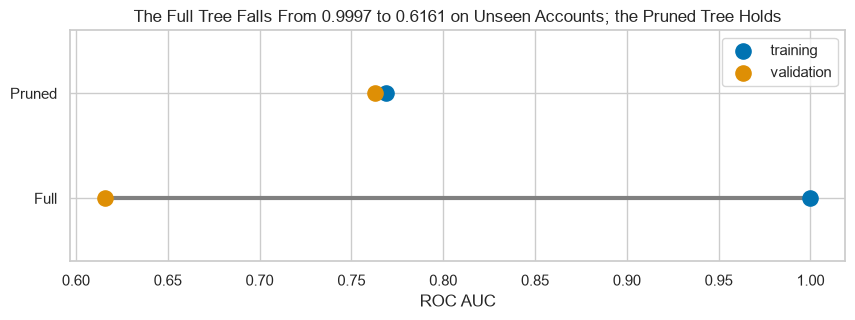

In [8]:
# Course 4's dumbbell: training against validation ROC AUC, one row per tree
fig, ax = plt.subplots(figsize=(10, 3))
ax.hlines(course4.index, course4["validation"], course4["training"], color="gray", linewidth=3)
ax.scatter(course4["training"], course4.index, s=120, label="training", zorder=3)
ax.scatter(course4["validation"], course4.index, s=120, label="validation", zorder=3)
ax.set_ylim(-0.6, 1.6)
ax.set_xlabel("ROC AUC")
ax.set_title("The Full Tree Falls From 0.9997 to 0.6161 on Unseen Accounts; the Pruned Tree Holds")
ax.legend(loc="upper right")
plt.show()

In [9]:
# the full tree's output for each validation account: how many are exactly 0 or 1?
full_outputs = full_tree.predict_proba(X_valid)[:, 1]
print("Outputs at exactly 0 or 1:", round(((full_outputs == 0) | (full_outputs == 1)).mean() * 100, 1), "percent")

Outputs at exactly 0 or 1: 97.7 percent


The full tree: 2,750 leaves, ROC AUC 0.9997 on its own rows and 0.6161 on the validation rows.

The pruned tree: 12 leaves, 0.7691 and 0.7627.

Course 4 read the full tree's gap as memorising, and 97.7 percent of its outputs on new accounts are exactly 0 or 1.

**Course 4 asked how much a tree memorises. Today asks how much of a tree is the luck of its 18,000 rows. To see that, we need other sets of 18,000.**

# The Bootstrap

Course 4's Day 3 drew 615 bonds with replacement, `rng.choice(615, size=615)`, and refitted a regression on each draw.
A **bootstrap sample** is that draw: as many rows as the data holds, each picked at random with replacement, so a row can be picked twice or not at all.
Today the same draw runs on the 18,000 training accounts.

**Predict 1**

Q. One bootstrap sample draws 18,000 positions from the 18,000 training rows. How many training accounts are never drawn? Write down a number.

## One Bootstrap Sample

`np.unique` returns each distinct value of an array once.

In [10]:
# one generator, seeded, for the random draws
rng = np.random.default_rng(SEED)

# 18,000 row positions drawn with replacement from the 18,000 training rows
n = len(X_train)
picks = rng.choice(n, size=n)
distinct = len(np.unique(picks))
print("Positions drawn:", len(picks), " Distinct accounts:", distinct)
print("Never drawn:", n - distinct, " Share:", round((n - distinct) / n * 100, 2), "percent")

Positions drawn: 18000  Distinct accounts: 11383
Never drawn: 6617  Share: 36.76 percent


18,000 positions, yet only 11,383 distinct accounts.

6,617 accounts, 36.76 percent of the training rows, are never drawn.

## How Often Each Account Was Drawn

`np.bincount(picks, minlength=n)` counts how often each position from 0 to n - 1 appears in `picks`.

In [11]:
# times each training account was drawn, then how many accounts were drawn 0, 1, 2, ... times
times = np.bincount(picks, minlength=n)
drawn_counts = pd.Series(times).value_counts().sort_index()
drawn_counts

0    6617
1    6662
2    3236
3    1150
4     268
5      58
6       9
Name: count, dtype: int64

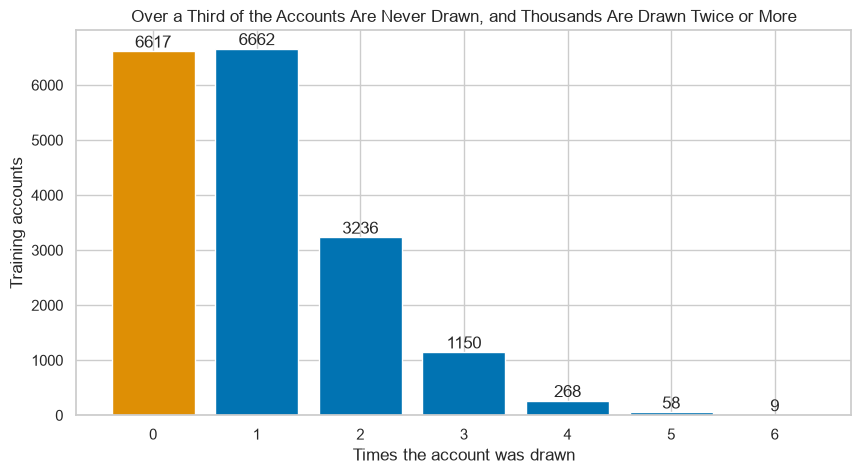

In [12]:
# accounts by the number of times drawn, the never-drawn bar highlighted
colours = ["C1" if k == 0 else "C0" for k in drawn_counts.index]
fig, ax = plt.subplots()
bars = ax.bar(drawn_counts.index, drawn_counts.values, color=colours)
ax.bar_label(bars, fmt="%.0f")
ax.set_xlabel("Times the account was drawn")
ax.set_ylabel("Training accounts")
ax.set_title("Over a Third of the Accounts Are Never Drawn, and Thousands Are Drawn Twice or More")
plt.show()

6,662 accounts are drawn once, 3,236 twice, and 9 six times.

The sample still holds 18,000 rows: the repeats fill the places of the accounts left out.

## Ten Accounts, Drawn by Hand

The same draw on a file of 10 accounts, four times, small enough to see every pick.

In [13]:
# four bootstrap draws of 10 positions from a generator of their own: times each account was drawn
small_rng = np.random.default_rng(SEED)
small_draws = pd.DataFrame([np.bincount(small_rng.choice(10, size=10), minlength=10) for draw in range(4)],
                           index=["draw 1", "draw 2", "draw 3", "draw 4"])
small_draws

,0,1,2,3,4,5,6,7,8,9
draw 1,3,0,1,0,2,0,2,1,1,0
draw 2,0,1,0,0,1,2,0,4,1,1
draw 3,0,1,0,1,2,2,1,1,1,1
draw 4,2,0,2,0,1,1,1,0,3,0


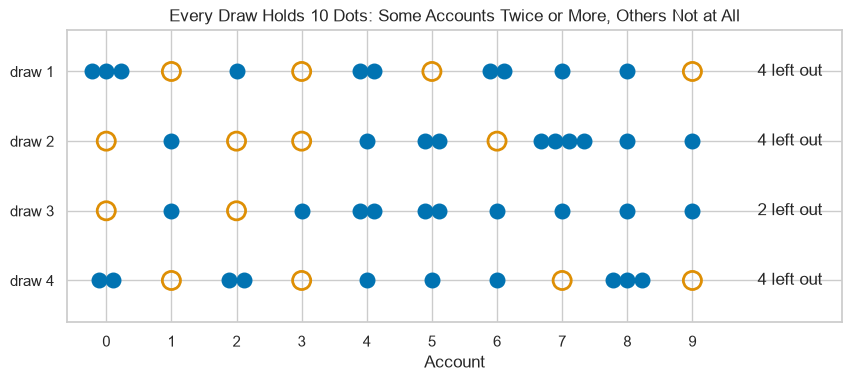

In [14]:
# a dot stack: one dot for each time an account was drawn, an empty ring where it was left out
fig, ax = plt.subplots(figsize=(10, 3.8))
for row in range(4):
    drawn = small_draws.iloc[row]
    for account in range(10):
        if drawn[account] == 0:
            ax.scatter(account, row, s=170, facecolor="none", edgecolor="C1", linewidth=2)
        for k in range(drawn[account]):
            ax.scatter(account + 0.22 * k - 0.11 * (drawn[account] - 1), row, s=110, color="C0")
    ax.text(10, row, str((drawn == 0).sum()) + " left out", va="center")
ax.set(xticks=range(10), yticks=range(4), yticklabels=small_draws.index, xlim=(-0.6, 11.3), ylim=(3.6, -0.6))
ax.set_xlabel("Account")
ax.set_title("Every Draw Holds 10 Dots: Some Accounts Twice or More, Others Not at All")
plt.show()

Each row holds ten dots, the same size as the file.

The rings are the accounts that draw left out: 4, 4, 2 and 4.

### Interpretation of the Share Left Out

One pick misses a given account with chance 1 - 1/n, so all n picks miss it with chance (1 - 1/n)^n.

In [15]:
# the chance an account is never drawn in a sample the size of the training rows, and e to the power -1
print("(1 - 1/n)^n at n = 18,000:", round((1 - 1 / n) ** n, 4))
print("e^-1:", round(np.exp(-1), 4))

(1 - 1/n)^n at n = 18,000: 0.3679
e^-1: 0.3679


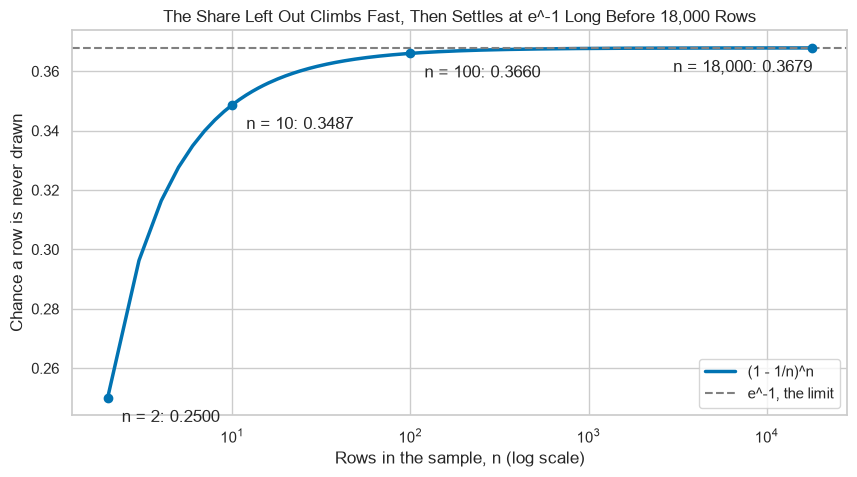

In [16]:
# the share left out for every sample size from 2 to 18,000, on a log axis
sizes = np.arange(2, n + 1)
plt.plot(sizes, (1 - 1 / sizes) ** sizes, linewidth=2.5, label="(1 - 1/n)^n")
plt.axhline(np.exp(-1), color="gray", linestyle="--", label="e^-1, the limit")
for size in [2, 10, 100, n]:
    share = (1 - 1 / size) ** size
    plt.scatter(size, share, color="C0", zorder=3)
    plt.text(size * 1.2 if size < n else size, share - 0.004, f"n = {size:,}: {share:.4f}", va="top",
             ha="left" if size < n else "right")
plt.xscale("log")
plt.xlabel("Rows in the sample, n (log scale)")
plt.ylabel("Chance a row is never drawn")
plt.title("The Share Left Out Climbs Fast, Then Settles at e^-1 Long Before 18,000 Rows")
plt.legend(loc="lower right")
plt.show()

A sample of 2 leaves out a row a quarter of the time, a sample of 10 about 35 percent of the time.

By 100 rows the share is within a fraction of a point of its limit, e^-1, about 0.368.

So every bootstrap sample of the card file leaves out about 36.8 percent of the accounts, and holds about 63.2 percent.

**Every bootstrap sample is another plausible 18,000: about two thirds of the same accounts, some counted twice, the rest absent. Fit a tree on each and compare.**

# Ten Samples, Ten Trees

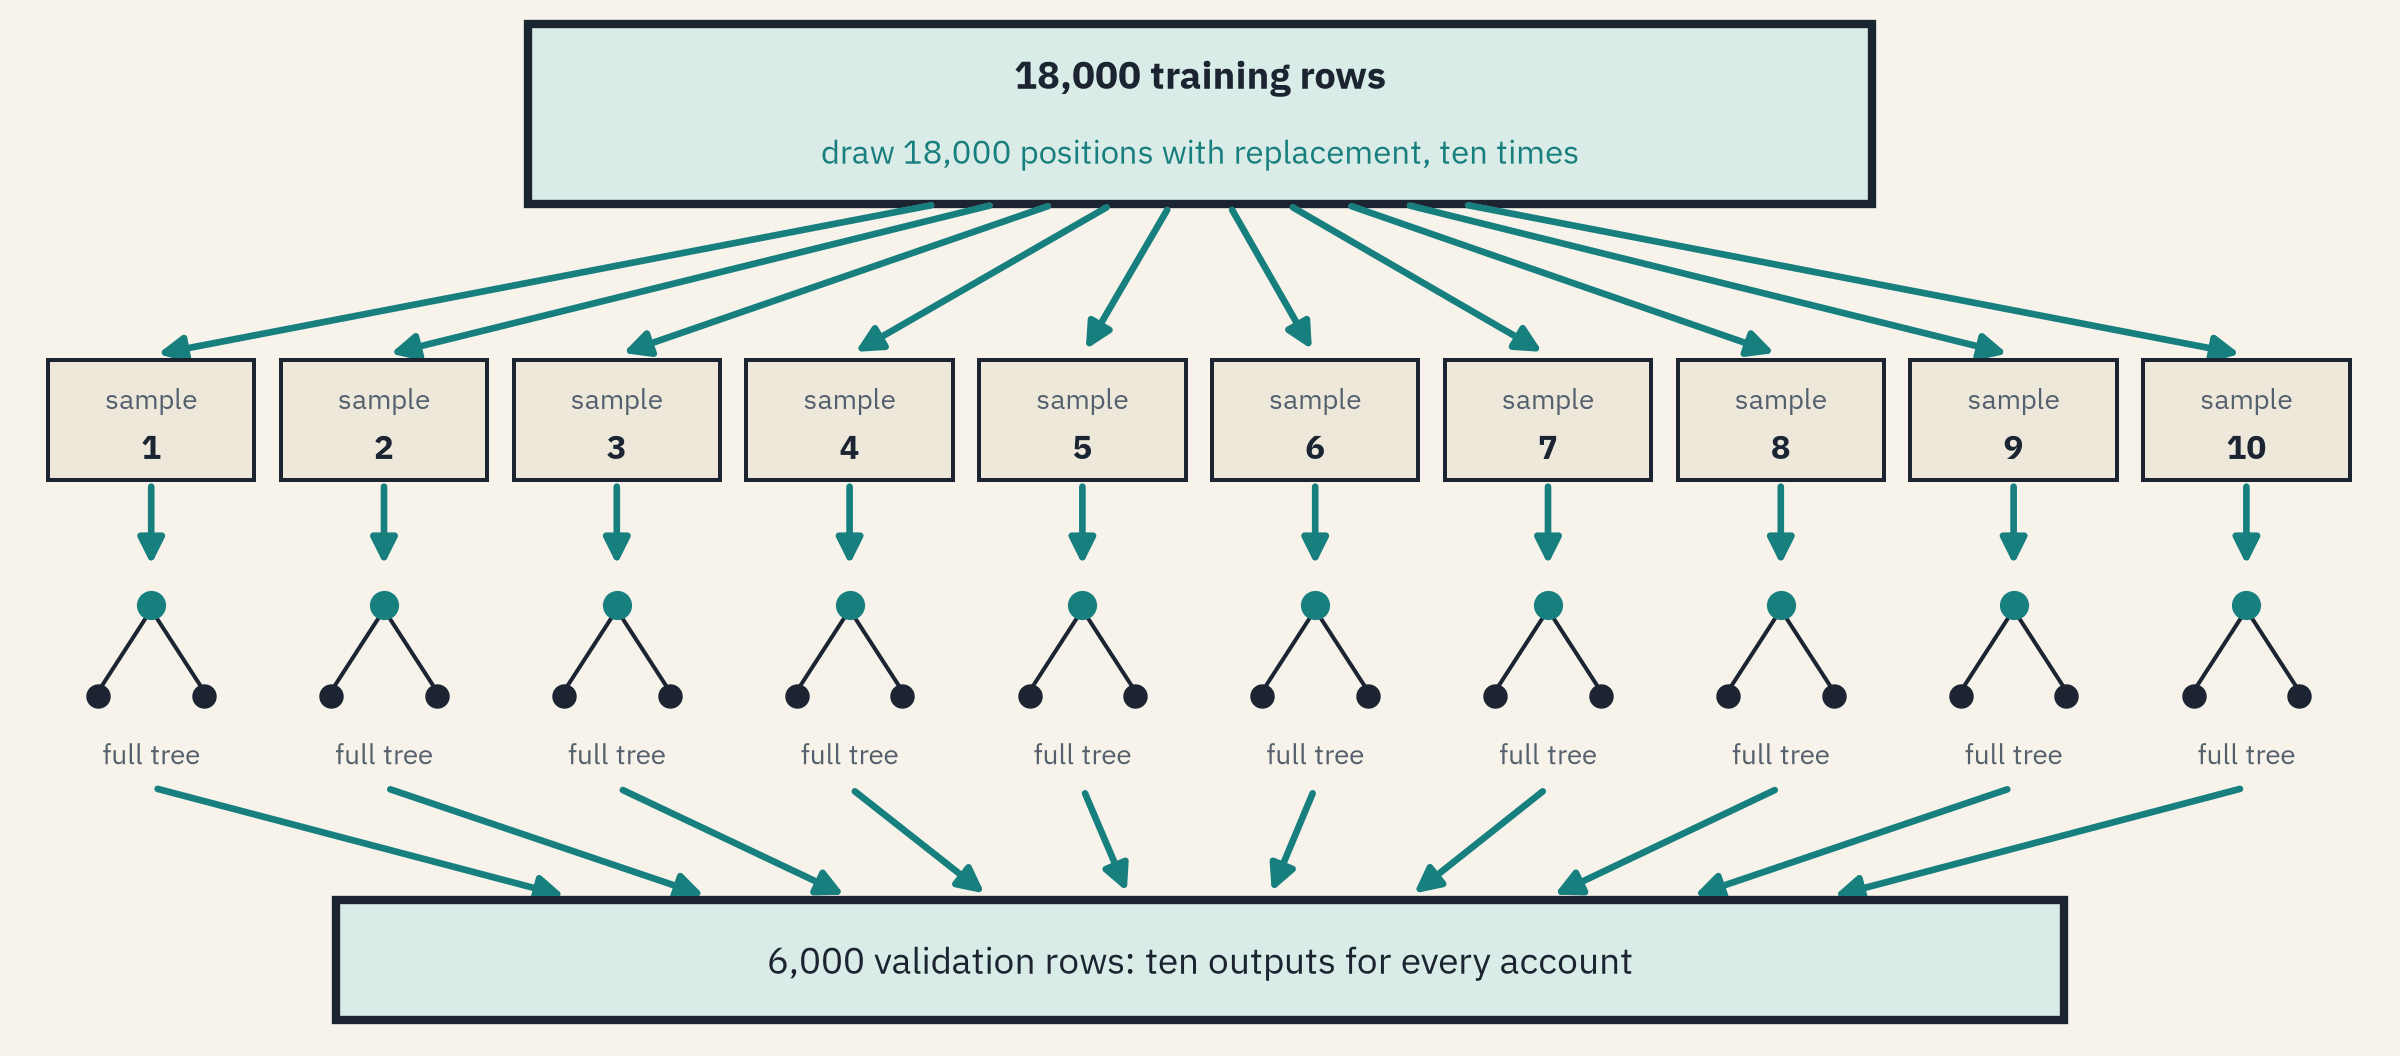

## Fitting a Full Tree on Each Sample

`X_train.iloc[sample]` takes the rows at those positions, repeats included, so an account drawn twice counts twice in the fit.

In [17]:
# a fresh generator with the same seed, so the first sample is the draw above
rng = np.random.default_rng(SEED)

# ten bootstrap samples, and a full tree fitted on each
samples, full_trees = [], []
for k in range(10):
    sample = rng.choice(n, size=n)
    samples.append(sample)
    full_trees.append(DecisionTreeClassifier(random_state=SEED).fit(X_train.iloc[sample], y_train.iloc[sample]))
print("The first sample is the draw above:", np.array_equal(samples[0], picks))

The first sample is the draw above: True


## What the Ten Trees Ask

`.tree_.feature[node]` is the number of the column a node asks about, and `.tree_.threshold[node]` its threshold.
Node 0 is the root, and `.tree_.children_left` (Course 4's Day 9) and `.tree_.children_right` give the first node on each side of it.

In [18]:
# a tree's question at one node, as text
def question(tree, node):
    return FEATURES[tree.tree_.feature[node]] + " <= " + str(round(tree.tree_.threshold[node], 1))

# for each tree: the root's question, the next question on each side, its size and its validation ROC AUC
tops = pd.DataFrame({"root": [question(t, 0) for t in full_trees],
                     "left": [question(t, t.tree_.children_left[0]) for t in full_trees],
                     "right": [question(t, t.tree_.children_right[0]) for t in full_trees],
                     "leaves": [t.get_n_leaves() for t in full_trees],
                     "depth": [t.get_depth() for t in full_trees],
                     "ROC AUC": [auc(t, X_valid, y_valid) for t in full_trees]}, index=range(1, 11))
tops

,root,left,right,leaves,depth,ROC AUC
1,PAY_0 <= 1.5,PAY_2 <= 1.5,PAY_3 <= -0.5,1877,43,0.6219
2,PAY_0 <= 1.5,PAY_0 <= 0.5,BILL_AMT1 <= 586.5,1878,35,0.6016
3,PAY_0 <= 1.5,PAY_2 <= 1.5,BILL_AMT1 <= 577.0,1902,37,0.6057
4,PAY_0 <= 1.5,PAY_2 <= 1.5,PAY_3 <= -0.5,1905,34,0.6145
5,PAY_0 <= 1.5,PAY_2 <= 1.5,PAY_3 <= -0.5,1856,35,0.6223
6,PAY_0 <= 1.5,PAY_2 <= 1.5,BILL_AMT1 <= 586.5,1895,41,0.6124
7,PAY_0 <= 1.5,PAY_2 <= 1.5,BILL_AMT1 <= 1045.5,1887,36,0.6220
8,PAY_0 <= 1.5,PAY_2 <= 1.5,PAY_3 <= -0.5,1891,34,0.6111
9,PAY_0 <= 1.5,PAY_0 <= 0.5,BILL_AMT1 <= 1578.0,1918,36,0.6262
10,PAY_0 <= 1.5,PAY_2 <= 1.5,BILL_AMT1 <= 2207.5,1895,38,0.6296


Every root asks `PAY_0 <= 1.5`, Course 4's root.

The left side asks `PAY_2 <= 1.5` in 8 trees and `PAY_0 <= 0.5` in 2.

The right side asks `PAY_3 <= -0.5` in 4 trees and about `BILL_AMT1` in 6, at five different thresholds.

1,856 to 1,918 leaves, 34 to 43 questions deep.

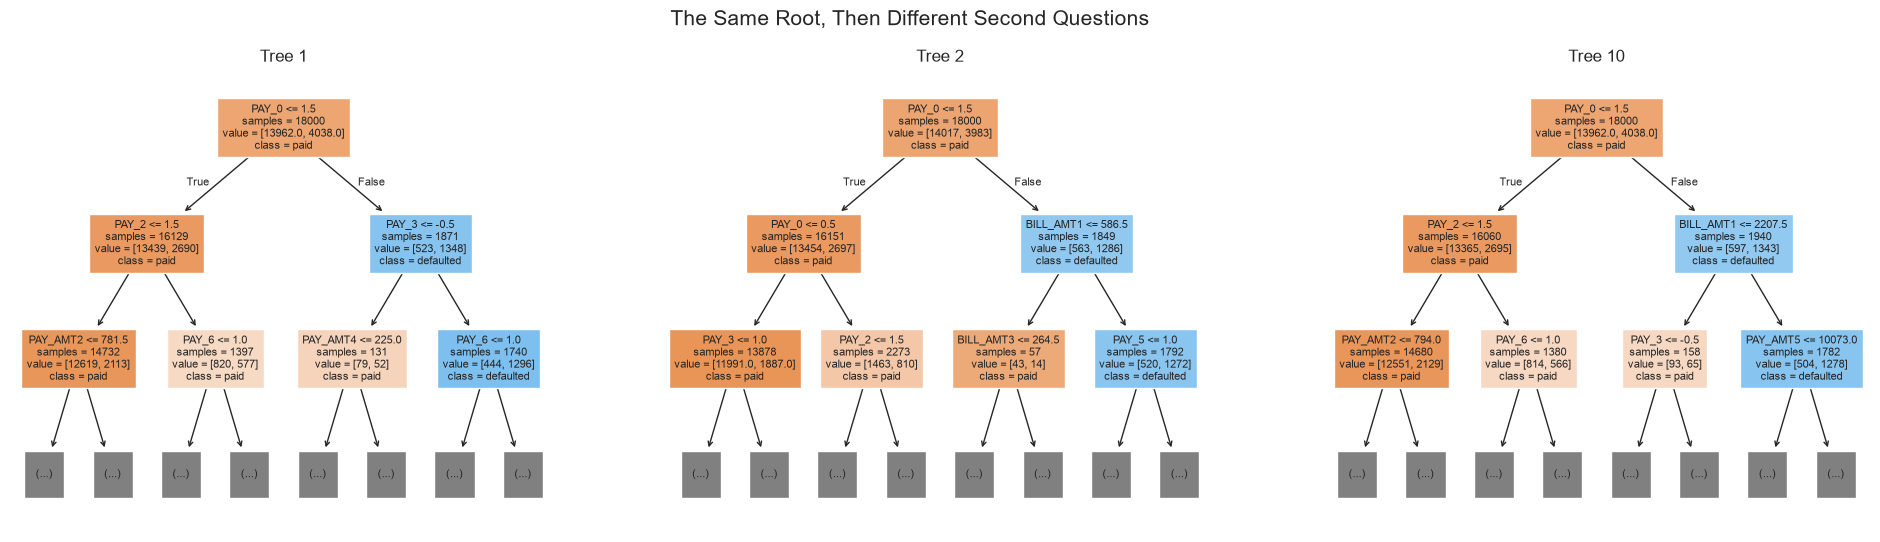

In [19]:
# the top two levels of three of the trees, side by side
fig, axes = plt.subplots(1, 3, figsize=(24, 6))
for ax, k in zip(axes, [1, 2, 10]):
    plot_tree(full_trees[k - 1], max_depth=2, feature_names=FEATURES, class_names=["paid", "defaulted"], filled=True,
              impurity=False, fontsize=8, ax=ax)
    ax.set_title(f"Tree {k}")
fig.suptitle("The Same Root, Then Different Second Questions", fontsize=15)
plt.show()

`plot_tree(max_depth=2)` draws only the top two levels of a tree, so a tree of 1,900 leaves fits on the page.

The root asks the same question in all three; below it, each sample's luck picks the next question.

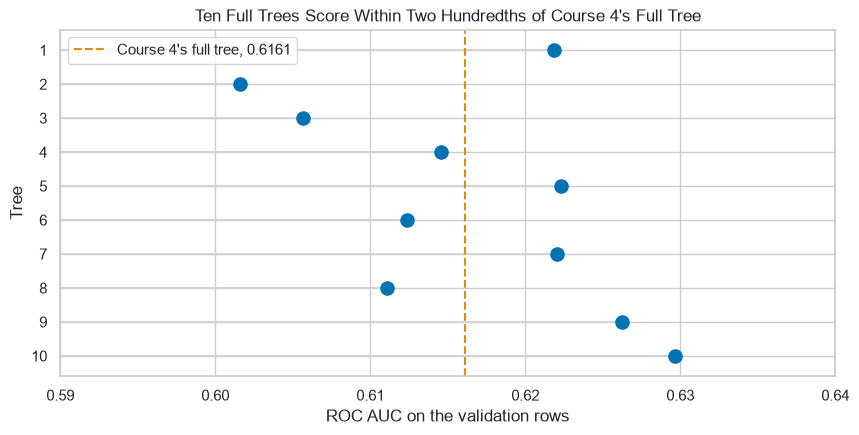

In [20]:
# the ten trees' validation ROC AUC as dots, Course 4's full tree as a dashed line
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hlines(tops.index, 0.59, tops["ROC AUC"], color="lightgray")
ax.scatter(tops["ROC AUC"], tops.index, s=90, zorder=3)
ax.axvline(course4.loc["Full", "validation"], color="C1", linestyle="--", label="Course 4's full tree, 0.6161")
ax.set(yticks=tops.index, xlim=(0.59, 0.64), ylim=(10.6, 0.4))
ax.set_xlabel("ROC AUC on the validation rows")
ax.set_ylabel("Tree")
ax.set_title("Ten Full Trees Score Within Two Hundredths of Course 4's Full Tree")
ax.legend(loc="upper left")
plt.show()

The ten trees score 0.6016 to 0.6296, around Course 4's full tree at 0.6161.

**The ten trees agree at the top and score alike. Next we ask whether they agree about any one account.**

# One Account, Ten Answers

**Predict 2**

Q. Of the 6,000 validation accounts, on how many will the ten trees not all give the same flag at 0.5? Write down a number.

## Ten Outputs per Account

In [21]:
# each tree's output for each validation account: one column per tree
outputs = pd.DataFrame()
for k, tree in enumerate(full_trees, start=1):
    outputs["tree " + str(k)] = tree.predict_proba(X_valid)[:, 1]
outputs.head()

,tree 1,tree 2,tree 3,tree 4,tree 5,tree 6,tree 7,tree 8,tree 9,tree 10
0,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000
2,0.5714,0.7000,0.7000,0.5714,0.3000,0.4706,0.4783,0.6154,0.4762,0.5714
3,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


A **vote** here is one tree flagging an account at 0.5, so an account gets 0 to 10 votes.
`.std(axis=1)` takes the standard deviation along each row, across the ten trees.

In [22]:
# each account's votes, and the accounts on which the ten trees do not all agree
votes = (outputs >= 0.5).sum(axis=1)
split = (votes > 0) & (votes < 10)
print("Accounts the ten trees split:", split.sum(), "of", len(votes), " Share:", round(split.mean() * 100, 1), "percent")

# how far an account's ten outputs spread, on average over the accounts
print("Mean standard deviation of an account's ten outputs:", round(outputs.std(axis=1).mean(), 4))

Accounts the ten trees split: 4370 of 6000  Share: 72.8 percent
Mean standard deviation of an account's ten outputs: 0.3009


4,370 accounts, 72.8 percent, get a flag from some trees and not from others.

Like Course 4's full tree, each tree gives almost only 0 or 1, as the first rows above show, so an account's ten outputs spread by about 0.30 on average.

## How Many Trees Flag Each Account

In [23]:
# validation accounts by their votes, and the default rate among them
by_votes = y_valid.groupby(votes.values).agg(["size", "mean"])
by_votes.columns = ["accounts", "default rate"]
by_votes

,accounts,default rate
0,1557,0.0854
1,1346,0.1374
2,959,0.1856
3,675,0.2281
4,434,0.2857
5,313,0.3866
6,218,0.5275
7,170,0.5824
8,162,0.6543
9,93,0.6344


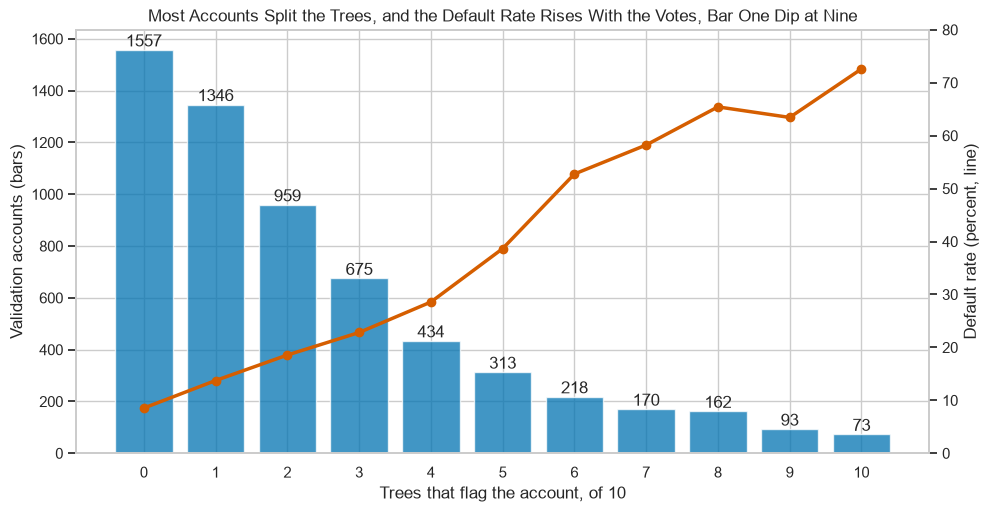

In [24]:
# accounts by votes as bars, the default rate as a line on a second axis that shares the x axis
fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.bar(by_votes.index, by_votes["accounts"], color="C0", alpha=0.75)
ax.bar_label(bars, fmt="%.0f")
ax.set(xticks=range(11), xlabel="Trees that flag the account, of 10", ylabel="Validation accounts (bars)")
rate_ax = ax.twinx()
rate_ax.plot(by_votes.index, by_votes["default rate"] * 100, color="C3", marker="o", linewidth=2.5)
rate_ax.set(ylim=(0, 80), ylabel="Default rate (percent, line)")
rate_ax.grid(False)
ax.set_title("Most Accounts Split the Trees, and the Default Rate Rises With the Votes, Bar One Dip at Nine")
plt.show()

`ax.twinx()` adds a second y axis on the right that shares the x axis, so counts and rates sit on one chart.

1,557 accounts get no flag, and 8.5 percent of them defaulted; 73 accounts get all ten, and 72.6 percent defaulted.

The default rate climbs with the votes at every step but one: 65.4 percent at eight trees, 63.4 at nine (93 accounts).

### Interpretation of the Votes

Each tree is almost always certain about an account, and the ten are certain in different ways.

**Variance** is how far a model's output for the same account moves when the model is fitted on another sample.

The votes still sort the accounts: their share is a steadier number than any one tree's flag.

**One full tree's flag is mostly luck, yet the share of trees that flag an account sorts the accounts. That share is an average. Before averaging, try steadier trees.**

# Shallow Trees on the Same Samples

## Ten Depth-3 Trees

In [25]:
# the same ten samples, each tree allowed three questions
shallow_trees = [DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_train.iloc[s], y_train.iloc[s])
                 for s in samples]
shallow = pd.DataFrame()
for k, tree in enumerate(shallow_trees, start=1):
    shallow["tree " + str(k)] = tree.predict_proba(X_valid)[:, 1]
shallow_votes = (shallow >= 0.5).sum(axis=1)

In [26]:
# their roots, their scores, and how far an account's ten outputs spread
shallow_auc = [roc_auc_score(y_valid, shallow[column]) for column in shallow]
print("Roots:", set([question(t, 0) for t in shallow_trees]))
print("ROC AUC:", round(min(shallow_auc), 4), "to", round(max(shallow_auc), 4))
print("Mean standard deviation of an account's ten outputs:", round(shallow.std(axis=1).mean(), 4))
print("Accounts the ten trees split:", ((shallow_votes > 0) & (shallow_votes < 10)).sum())

Roots: {'PAY_0 <= 1.5'}
ROC AUC: 0.7098 to 0.7327
Mean standard deviation of an account's ten outputs: 0.0307
Accounts the ten trees split: 202


The same root in all ten, and every depth-3 tree scores above every full tree.

An account's ten outputs spread about a tenth as much, and the trees split 202 accounts instead of 4,370.

### Your Turn: Deepen the Trees

Six validation accounts split the ten full trees 5 to 5.
The next cell fits the ten trees once at each depth the dropdown offers; `None` means no limit.

In [27]:
# six validation accounts on which the ten full trees split 5 to 5
six = votes[votes == 5].index[:6]

# at each depth: ten trees on the same ten samples, kept as their outputs for the six accounts (a row per account)
depth_options = [1, 2, 3, 4, 6, 8, 12, 20, None]
six_outputs = {}
for depth in depth_options:
    depth_trees = [DecisionTreeClassifier(max_depth=depth, random_state=SEED).fit(X_train.iloc[s], y_train.iloc[s])
                   for s in samples]
    six_outputs[depth] = pd.DataFrame([t.predict_proba(X_valid.iloc[six])[:, 1] for t in depth_trees]).T

In [28]:
# the ten outputs for each of the six accounts as dots, their mean as a bar, the flag line dashed
def strips(depth, ax):
    table = six_outputs[depth]
    for row in range(6):
        ax.scatter(table.iloc[row], [row] * 10, s=90, alpha=0.5, color="C0")
        ax.scatter(table.iloc[row].mean(), row, marker="|", s=900, linewidth=3, color="C3")
    ax.axvline(0.5, color="gray", linestyle="--")
    ax.set(yticks=range(6), yticklabels=["validation row " + str(a) for a in six], xlim=(-0.05, 1.05), ylim=(5.6, -0.6))
    ax.set_xlabel("A tree's output for the account (dots), the mean of ten (bar)")
    ax.set_title(f"max_depth={depth}: mean spread {table.std(axis=1).mean():.4f}")

Pick a depth and watch the dots: each is one tree's output for the account.

In [29]:
# your turn: pick a depth and watch the ten trees' outputs for the six accounts
def draw_strips(depth=None):
    fig, ax = plt.subplots(figsize=(10, 4.5))
    strips(depth, ax)
    plt.show()

interact(draw_strips, depth=depth_options);

interactive(children=(Dropdown(description='depth', options=(1, 2, 3, 4, 6, 8, 12, 20, None), value=None), Out…

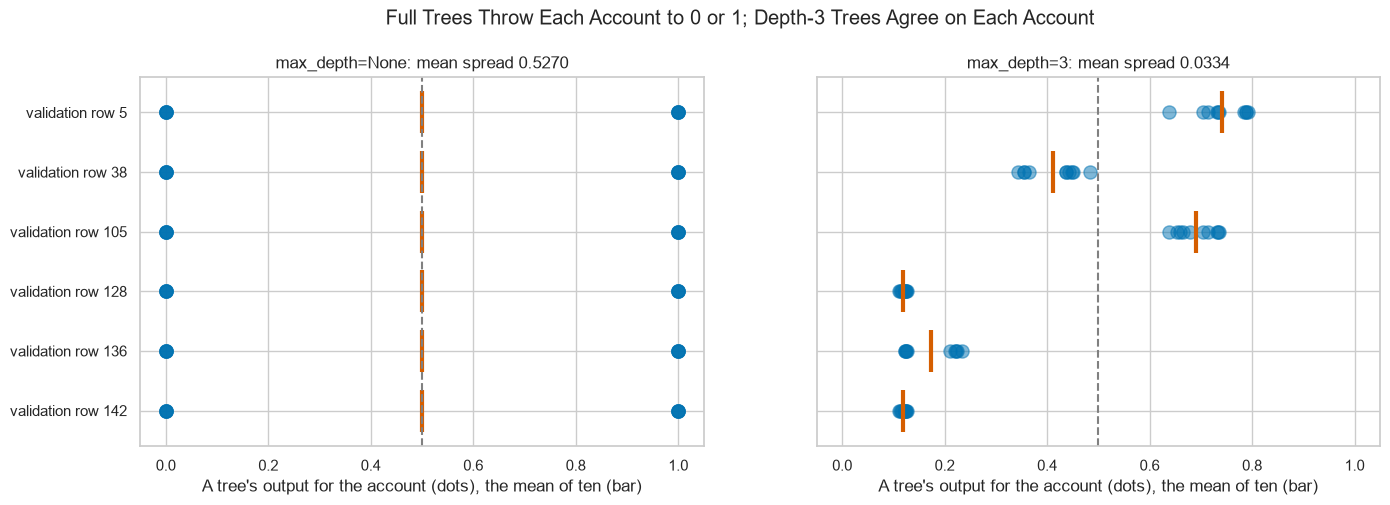

In [30]:
# the dropdown's starting depth (no limit) beside depth 3, drawn as a still picture (dropdowns do not run on GitHub)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), sharey=True)
strips(None, axes[0])
strips(3, axes[1])
fig.suptitle("Full Trees Throw Each Account to 0 or 1; Depth-3 Trees Agree on Each Account", y=1.02)
plt.show()

With no limit, each account gets five outputs of exactly 1 and five of exactly 0, so the mean sits on the flag line: a coin toss.

At depth 3 each account's ten dots sit close together, a mean spread of 0.0334 against 0.5270, and two of the six accounts land above the flag line.

### Interpretation of Bias and Variance

**Bias** is the gap between a model's output averaged over many samples and the pattern in the data, left because the model is too simple to follow it.

Full trees have low bias and high variance; depth-3 trees have the reverse.

Averaging ten outputs shrinks their spread, never the bias they share.

Trading one against the other, through depth here, is the **bias-variance trade-off**.

**Deep trees are noisy and shallow trees are limited. Averaging works on noise, so we average both kinds and compare.**

# Averaging the Trees

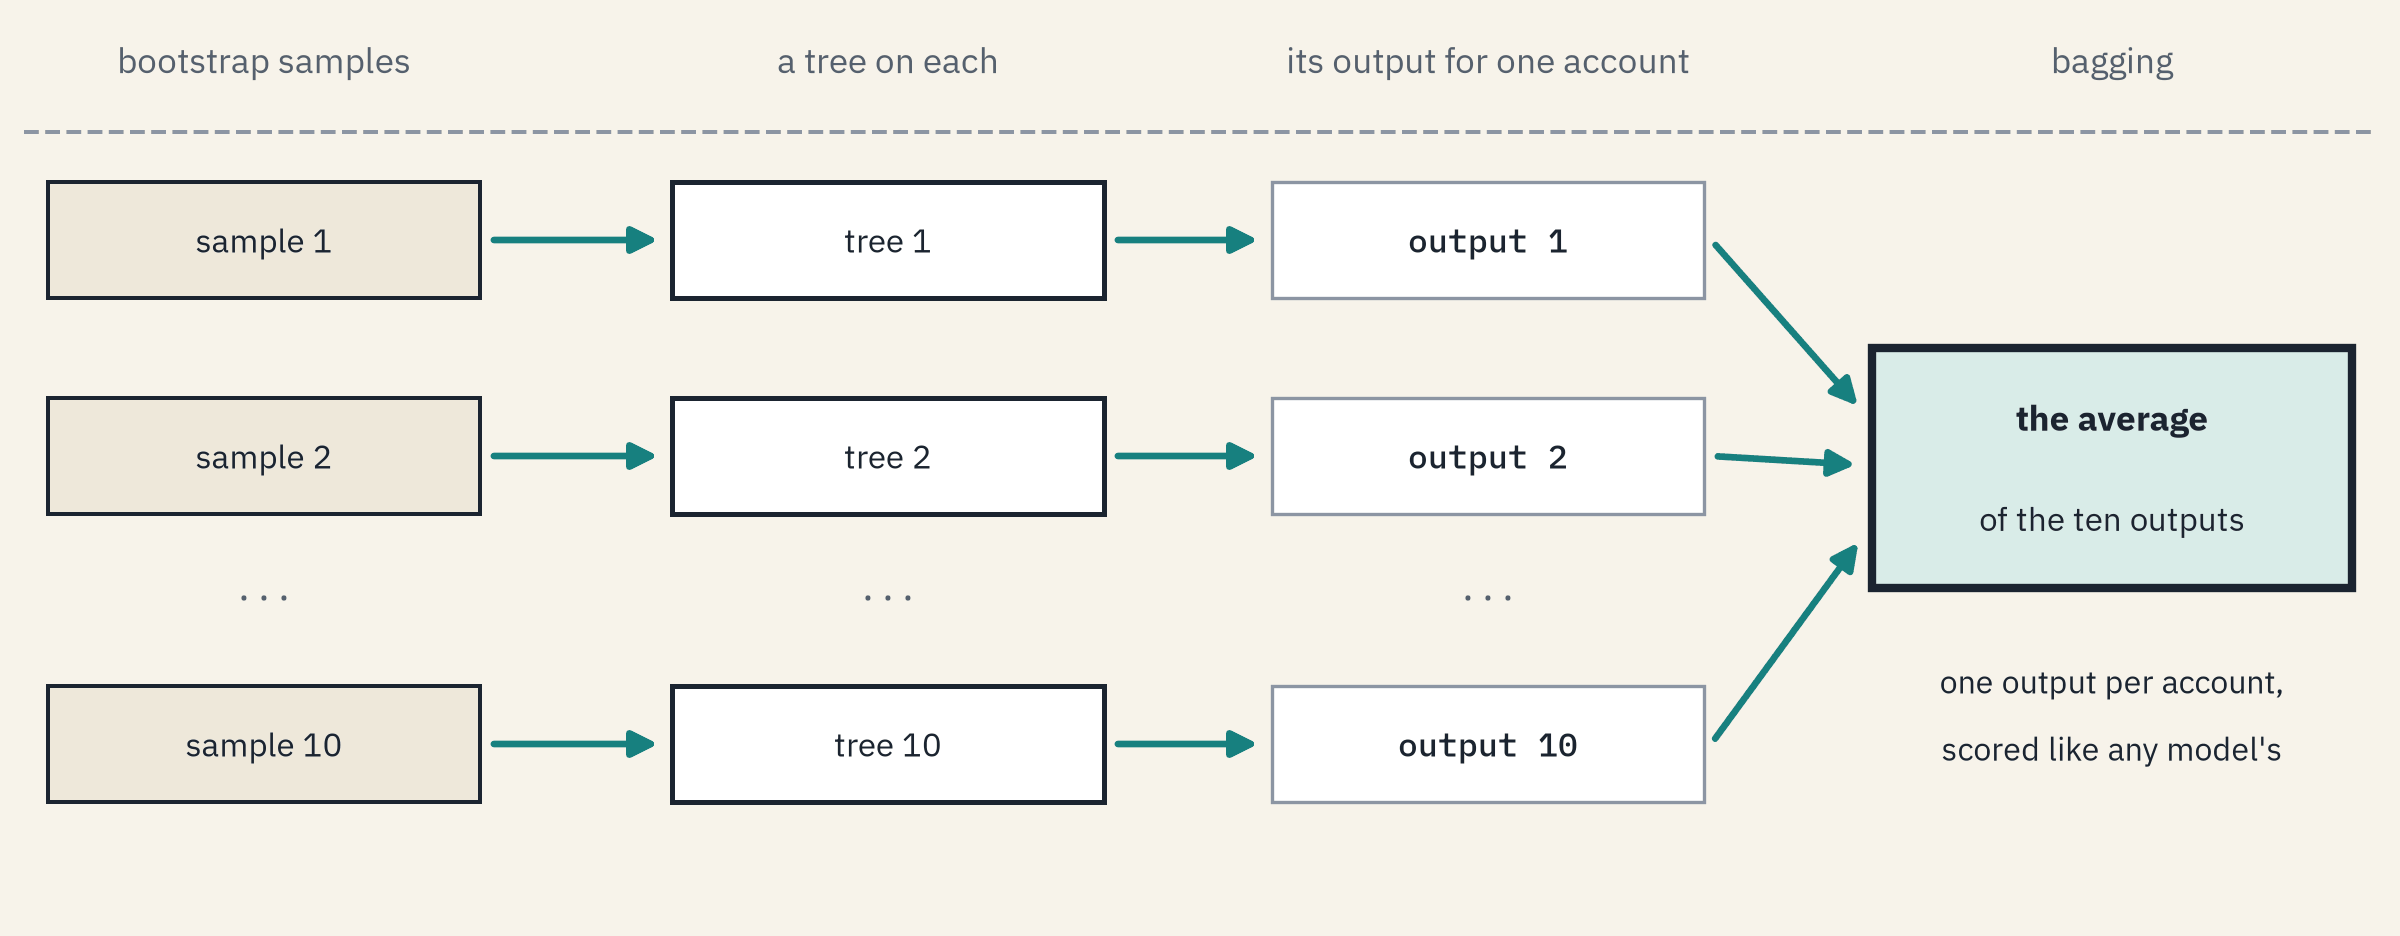

An **ensemble** is a model made of several models whose outputs are combined.
**Bagging**, short for bootstrap aggregating, fits a model on each bootstrap sample and averages their outputs.

> STORY: Leo Breiman named the method and published it as "Bagging predictors" in Machine Learning, volume 24, issue 2, pages 123 to 140, in August 1996. Source: https://api.crossref.org/works/10.1007/BF00058655

**Predict 3**

The ten full trees score 0.6016 to 0.6296 on the validation rows.

Q. What does the average of their ten outputs score? Write down a number.

## The Average of Ten Full Trees

In [31]:
# the average of each account's ten outputs, scored like any model's output
average = outputs.mean(axis=1)
print("ROC AUC:", round(roc_auc_score(y_valid, average), 4))
print("Average precision:", round(average_precision_score(y_valid, average), 4), " Distinct outputs:", average.nunique())

ROC AUC: 0.7352
Average precision: 0.4575  Distinct outputs: 104


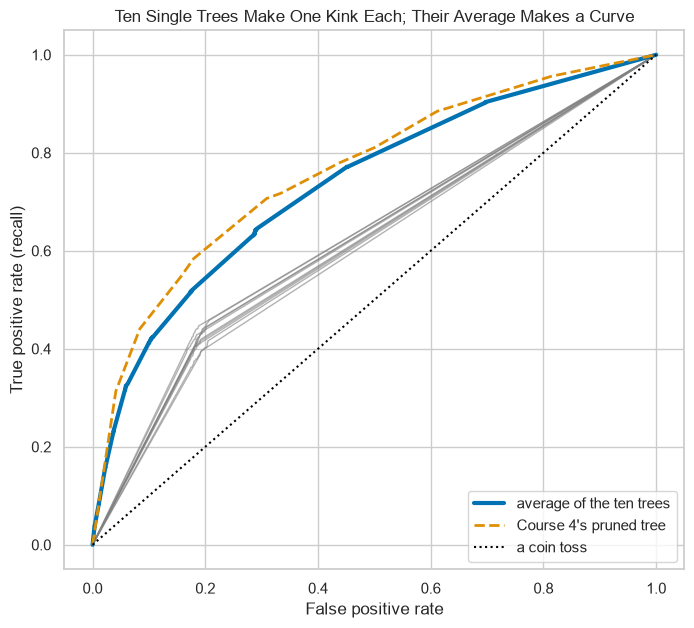

In [32]:
# ROC curves: the ten single trees thin, their average bold, Course 4's pruned tree dashed
fig, ax = plt.subplots(figsize=(8, 7))
for column in outputs:
    fpr, tpr, thresholds = roc_curve(y_valid, outputs[column])
    ax.plot(fpr, tpr, color="gray", linewidth=1, alpha=0.6)
fpr, tpr, thresholds = roc_curve(y_valid, average)
ax.plot(fpr, tpr, color="C0", linewidth=3, label="average of the ten trees")
fpr, tpr, thresholds = roc_curve(y_valid, pruned_tree.predict_proba(X_valid)[:, 1])
ax.plot(fpr, tpr, color="C1", linestyle="--", linewidth=2, label="Course 4's pruned tree")
ax.plot([0, 1], [0, 1], color="black", linestyle=":", label="a coin toss")
ax.set(xlabel="False positive rate", ylabel="True positive rate (recall)")
ax.set_title("Ten Single Trees Make One Kink Each; Their Average Makes a Curve")
ax.legend(loc="lower right")
plt.show()

Each single tree gives almost only 0 and 1, so its ROC curve is one kink, the gray lines.

The average takes 104 different values, so its curve bends smoothly, well above every single tree.

ROC AUC rises from at most 0.6296 to 0.7352, a gain of more than a tenth over the best single tree.

**Predict 4**

The ten depth-3 trees score 0.7098 to 0.7327.

Q. How much will their average add to the best of them? Write down a number.

## The Average of Ten Depth-3 Trees

In [33]:
# the average of the ten shallow trees, and its gain over the best single tree, for both kinds
shallow_average = shallow.mean(axis=1)
full_auc = tops["ROC AUC"]
print("Depth 3, average:", round(roc_auc_score(y_valid, shallow_average), 4),
      " Gain over the best:", round(roc_auc_score(y_valid, shallow_average) - max(shallow_auc), 4))
print("Full, average:", round(roc_auc_score(y_valid, average), 4),
      " Gain over the best:", round(roc_auc_score(y_valid, average) - full_auc.max(), 4))

Depth 3, average: 0.741  Gain over the best: 0.0083
Full, average: 0.7352  Gain over the best: 0.1056


The depth-3 average gains less than a hundredth; the full-tree average gained more than a tenth.

The depth-3 trees agreed already, so there was little noise left to cancel.

### Interpretation of the Gain

Averaging cancels much of the part of each tree's output that comes from its own sample's luck.

Every sample is drawn from the same 18,000 accounts, so the trees' luck partly agrees, and that shared part never cancels.

Later in this course, random forests make the trees less alike on purpose, so more of it cancels.

## Adding One Tree at a Time

In [34]:
# ROC AUC of the average of the first k trees, k = 1 to 10, for both kinds
first_k = pd.DataFrame({"full": [roc_auc_score(y_valid, outputs.iloc[:, :k].mean(axis=1)) for k in range(1, 11)],
                        "depth 3": [roc_auc_score(y_valid, shallow.iloc[:, :k].mean(axis=1)) for k in range(1, 11)]},
                       index=range(1, 11))

# the same for the full trees taken in 200 random orders, from the notebook's generator
orders = []
for i in range(200):
    order = rng.permutation(10)
    orders.append([roc_auc_score(y_valid, outputs.iloc[:, order[:k]].mean(axis=1)) for k in range(1, 11)])
orders = pd.DataFrame(orders, columns=range(1, 11))
first_k.T

,1,2,3,4,5,6,7,8,9,10
full,0.6219,0.6529,0.6712,0.6869,0.7018,0.7104,0.7202,0.7247,0.7290,0.7352
depth 3,0.7195,0.7300,0.7419,0.7406,0.7399,0.7392,0.7386,0.7385,0.7411,0.7410


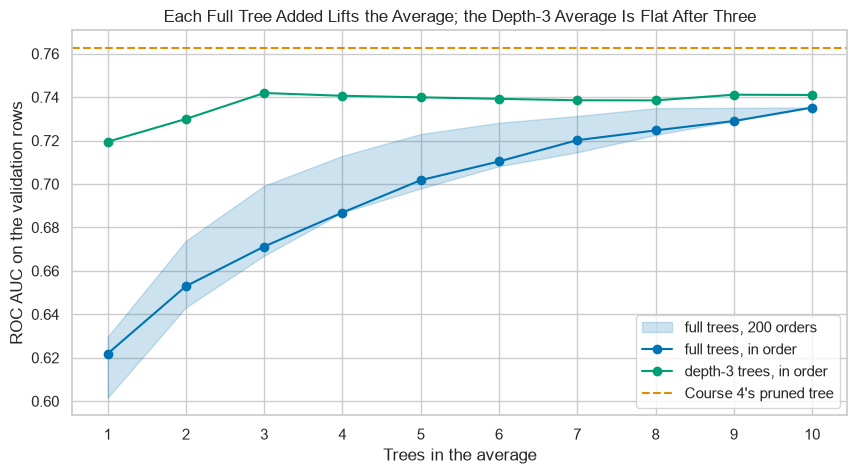

In [35]:
# the first k trees for each kind, with the band of the 200 orders for the full trees
plt.fill_between(range(1, 11), orders.min(), orders.max(), color="C0", alpha=0.2, label="full trees, 200 orders")
plt.plot(first_k.index, first_k["full"], marker="o", color="C0", label="full trees, in order")
plt.plot(first_k.index, first_k["depth 3"], marker="o", color="C2", label="depth-3 trees, in order")
plt.axhline(course4.loc["Pruned", "validation"], color="C1", linestyle="--", label="Course 4's pruned tree")
plt.xticks(range(1, 11))
plt.xlabel("Trees in the average")
plt.ylabel("ROC AUC on the validation rows")
plt.title("Each Full Tree Added Lifts the Average; the Depth-3 Average Is Flat After Three")
plt.legend(loc="lower right")
plt.show()

The full-tree average climbs with every tree added, and the 200 orders climb with it.

The band closes at 10 trees, where every order holds the same ten.

The depth-3 average stops moving after about three trees.

Neither line reaches Course 4's pruned tree at ten trees.

## Singles, Averages and Course 4's Tree

In [36]:
# per kind: the range of the ten single trees, the average of ten, and Course 4's pruned tree
kinds = pd.DataFrame({"lowest single": [full_auc.min(), min(shallow_auc)],
                      "highest single": [full_auc.max(), max(shallow_auc)],
                      "average of ten": [roc_auc_score(y_valid, average), roc_auc_score(y_valid, shallow_average)]},
                     index=["Full trees", "Depth-3 trees"])
kinds

,lowest single,highest single,average of ten
Full trees,0.6016,0.6296,0.7352
Depth-3 trees,0.7098,0.7327,0.7410


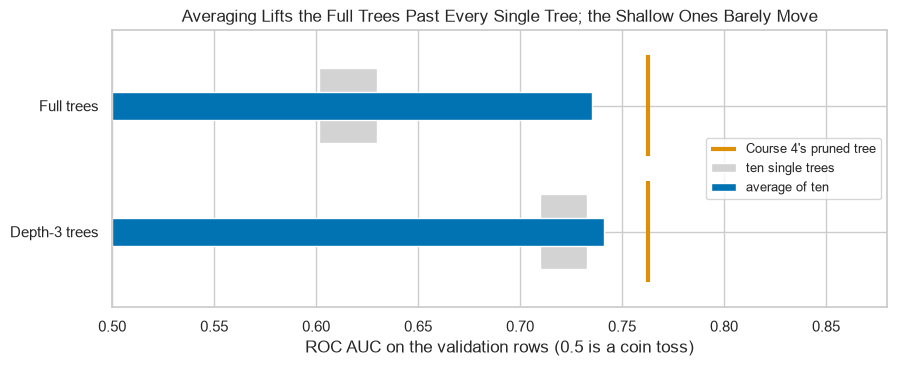

In [37]:
# a bullet chart: the singles' range as a wide gray band, the average as a narrow bar from 0.5, Course 4's tree as a tick
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.barh(kinds.index, kinds["highest single"] - kinds["lowest single"], left=kinds["lowest single"], height=0.6,
        color="lightgray", label="ten single trees")
ax.barh(kinds.index, kinds["average of ten"] - 0.5, left=0.5, height=0.22, color="C0", label="average of ten")
pruned_auc = course4.loc["Pruned", "validation"]
ax.vlines([pruned_auc, pruned_auc], [-0.4, 0.6], [0.4, 1.4], color="C1", linewidth=3, label="Course 4's pruned tree")
ax.set(xlim=(0.5, 0.88), ylim=(1.6, -0.6))
ax.set_xlabel("ROC AUC on the validation rows (0.5 is a coin toss)")
ax.set_title("Averaging Lifts the Full Trees Past Every Single Tree; the Shallow Ones Barely Move")
ax.legend(loc="center right", fontsize=9)
plt.show()

Averaging lifts the full trees by a tenth and the shallow ones by under a hundredth.

Neither ten-tree average reaches Course 4's pruned tree at 0.7627.

Day 2 grows the average to hundreds of trees with scikit-learn's own bagging.

**Averaging cancels the noise of deep trees and barely touches shallow ones; ten trees are not yet enough to pass Course 4's tree.**

# The Out-of-Bag Rows

The **out-of-bag rows** of a bootstrap sample are the training rows it never drew: about a third of them, never seen by the tree fitted on it.

## Rows a Tree Never Saw

In [38]:
# for each tree: the training rows its sample never drew, and its ROC AUC on them
rows = []
for sample, tree in zip(samples, full_trees):
    unseen = np.bincount(sample, minlength=n) == 0
    rows.append([unseen.sum(), auc(tree, X_train[unseen], y_train[unseen])])
oob = pd.DataFrame(rows, columns=["out-of-bag rows", "out-of-bag ROC AUC"], index=range(1, 11))
oob["validation ROC AUC"] = full_auc
oob

,out-of-bag rows,out-of-bag ROC AUC,validation ROC AUC
1,6617,0.6125,0.6219
2,6653,0.6211,0.6016
3,6606,0.6161,0.6057
4,6562,0.6237,0.6145
5,6619,0.6129,0.6223
6,6628,0.6227,0.6124
7,6592,0.6066,0.6220
8,6561,0.6210,0.6111
9,6516,0.6297,0.6262
10,6584,0.6246,0.6296


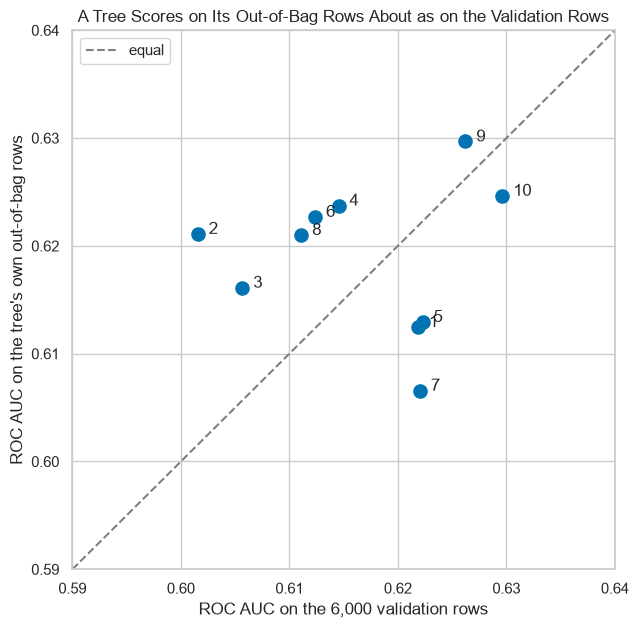

In [39]:
# each tree's out-of-bag ROC AUC against its validation ROC AUC, with the line where the two are equal
plt.figure(figsize=(7, 7))
plt.scatter(oob["validation ROC AUC"], oob["out-of-bag ROC AUC"], s=90)
for k in oob.index:
    plt.text(oob.loc[k, "validation ROC AUC"] + 0.001, oob.loc[k, "out-of-bag ROC AUC"], str(k))
plt.plot([0.59, 0.64], [0.59, 0.64], color="gray", linestyle="--", label="equal")
plt.xlim(0.59, 0.64)
plt.ylim(0.59, 0.64)
plt.xlabel("ROC AUC on the 6,000 validation rows")
plt.ylabel("ROC AUC on the tree's own out-of-bag rows")
plt.title("A Tree Scores on Its Out-of-Bag Rows About as on the Validation Rows")
plt.legend()
plt.show()

Each tree left 6,516 to 6,653 training rows unseen.

Its score on them lands within two hundredths of its score on the validation rows.

The rows a tree never saw are a free validation set for that tree.

**Every bootstrap tree carries its own unseen rows; Day 2 turns them into one score for the whole average.**

# Insights and Conclusion

One bootstrap sample leaves out about 37 percent of the accounts and counts others twice.

Ten full trees share Course 4's root and score alike, yet disagree on the flag of 73 percent of the accounts.

Deep trees are high variance and shallow trees high bias.

The average of ten deep trees beats the best of them by a tenth of ROC AUC; the shallow average gains little.

Out-of-bag rows score a tree about as unseen validation rows do.

**One tree is one draw of luck; Day 2 averages hundreds.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Draw a bootstrap sample with `rng.choice` and count what it leaves out.
* Say why the share left out settles near a fixed number as the file grows.
* Fit a tree on each of several samples and read their top questions with `.tree_`.
* Measure how far one account's output moves from tree to tree, and name variance and bias.
* Average trees, score the average, and find each tree's out-of-bag rows.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [40]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Trees With Leaves of 20 Accounts**

Q. Fit a tree with `min_samples_leaf=20` on each of the ten samples. Store the best single tree's validation ROC AUC in `ex1_best` and the ROC AUC of the ten trees' average in `ex1_average`.

In [41]:
# ten trees on the same samples, each leaf holding at least 20 training accounts
leaf_trees = [DecisionTreeClassifier(min_samples_leaf=20, random_state=SEED).fit(X_train.iloc[s], y_train.iloc[s])
              for s in samples]
leaf_outputs = pd.DataFrame()
for k, tree in enumerate(leaf_trees, start=1):
    leaf_outputs["tree " + str(k)] = tree.predict_proba(X_valid)[:, 1]

# the best single tree, the average of ten, and how far an account's ten outputs spread
ex1_best = max([roc_auc_score(y_valid, leaf_outputs[column]) for column in leaf_outputs])
ex1_average = roc_auc_score(y_valid, leaf_outputs.mean(axis=1))
print(round(ex1_best, 4), round(ex1_average, 4), round(leaf_outputs.std(axis=1).mean(), 4))

0.7188 0.7686 0.168


In [42]:
check("Exercise 1 the best single tree", ex1_best, 0.7187874481682277)
check("Exercise 1 the average of ten", ex1_average, 0.7686244843834235)

Exercise 1 the best single tree: correct
Exercise 1 the average of ten: correct


Leaves of at least 20 accounts spread an account's ten outputs about half as much as full trees.

Their average scores 0.7686, above Course 4's pruned tree at 0.7627: Day 2 picks this up.

### Exercise 2

**The Share Drawn at Other Sizes**

Q. For a file of 100 rows and one of 1,000,000, draw one bootstrap sample with a fresh `np.random.default_rng(SEED)` each, and store each sample's share of distinct positions in a dictionary `ex2_shares` with the keys `100` and `1000000`.

In [43]:
# a fresh generator for each size, one bootstrap sample, and its share of distinct positions
ex2_shares = {}
for size in [100, 1000000]:
    size_rng = np.random.default_rng(SEED)
    ex2_shares[size] = len(np.unique(size_rng.choice(size, size=size))) / size
print(ex2_shares)

{100: 0.66, 1000000: 0.632241}


In [44]:
check("Exercise 2 the shares drawn", ex2_shares, {100: 0.66, 1000000: 0.632241})

Exercise 2 the shares drawn: correct


### Exercise 3

**A Function for the Share**

Q. Write `distinct_share(picks, n_rows)` that returns the share of the `n_rows` positions that appear in `picks`, and store `distinct_share(samples[0], n)` in `ex3_share`.

In [45]:
# the distinct positions drawn, as a share of the rows
def distinct_share(picks, n_rows):
    return len(np.unique(picks)) / n_rows

ex3_share = distinct_share(samples[0], n)
print(ex3_share)

0.6323888888888889


In [46]:
check("Exercise 3 the first sample's share", ex3_share, 0.6323888888888889)

Exercise 3 the first sample's share: correct


### Exercise 4: AI check

**The Bootstrap That Drew Every Row**

You asked an AI assistant for a function that draws one bootstrap sample of row positions.
This came back.
It runs, and it returns 18,000 positions.
Test it, then find the one bug.

In [47]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def bootstrap_rows(n_rows):
    # draw n_rows row positions at random for one bootstrap sample
    rng = np.random.default_rng(SEED)
    return rng.permutation(n_rows)

ai_picks = bootstrap_rows(n)
print(len(ai_picks), "positions drawn")

18000 positions drawn


In [48]:
# the test: a bootstrap sample repeats some rows, so it holds fewer distinct positions than positions
assert len(np.unique(ai_picks)) < len(ai_picks), "every row drawn exactly once: a shuffle, not a bootstrap sample"

AssertionError: every row drawn exactly once: a shuffle, not a bootstrap sample

Q. Fix the function, and store the number of distinct positions in the fixed function's sample in `ex4_distinct`.

In [49]:
# the fix: choice draws with replacement, while permutation only shuffles every row once
def bootstrap_rows(n_rows):
    rng = np.random.default_rng(SEED)
    return rng.choice(n_rows, size=n_rows)

fixed_picks = bootstrap_rows(n)
assert len(np.unique(fixed_picks)) < len(fixed_picks)
ex4_distinct = len(np.unique(fixed_picks))
print(ex4_distinct)

11383


In [50]:
check("Exercise 4 the distinct positions", ex4_distinct, 11383)

Exercise 4 the distinct positions: correct


## Congratulations!

You opened Course 5 by drawing other training sets from the one you had.
You fitted ten trees on ten samples, watched them agree at the root and split on most of the accounts, and named that variance.
You saw shallow trees agree and stay limited, and an average of ten noisy trees beat every one of them.
You found the rows each tree never saw.
In Day 2 you grow the average to hundreds of trees and score it on those unseen rows.

[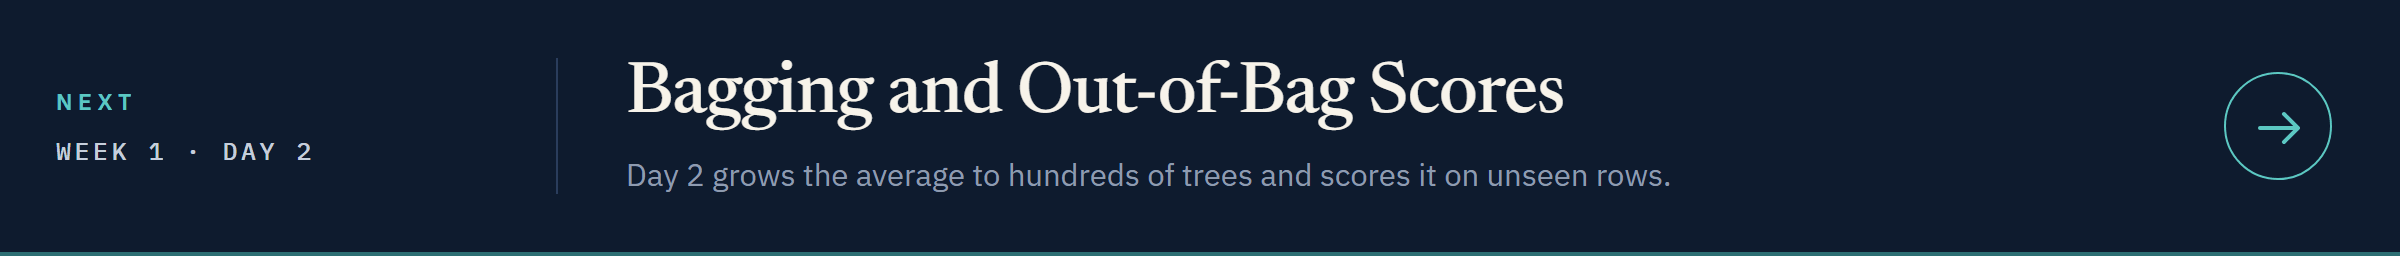](../day2/02_bagging_and_out_of_bag_scores.ipynb)

[Open Day 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week1/day2/02_bagging_and_out_of_bag_scores.ipynb)